# Module A — Nettoyage et exploration des données (EDA)

**Objectif :** obtenir un jeu de transactions propre et comprendre son contenu avant les analyses
de segmentation (module B), de règles d'association (module C) et de prédiction du churn (module D).

**Plan**
1. Chargement des données brutes
2. Nettoyage (avec journal des décisions)
3. Vue d'ensemble
4. Ventes dans le temps
5. Pays
6. Produits
7. Paniers et clients
8. Valeurs aberrantes
9. Conclusion

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from src.cleaning import clean, iqr_outlier_mask, load_raw
from src.config import CLEAN_PARQUET, FIGURES
from src.download_data import download

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")

## 1. Chargement des données brutes

In [2]:
download()
raw = load_raw()
print(f"{len(raw):,} lignes × {raw.shape[1]} colonnes")
raw.head()

Déjà présent : C:\Users\ffela\Documents\customer-analytics-data-mining\data\raw\online_retail_II.xlsx


1,067,371 lignes × 8 colonnes


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
missing = raw.isna().sum().to_frame("Valeurs manquantes")
missing["%"] = 100 * missing["Valeurs manquantes"] / len(raw)
missing

,Valeurs manquantes,%
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [4]:
print("Factures annulées (Invoice commençant par 'C') :", raw["Invoice"].astype(str).str.startswith("C").sum())
print("Quantités ≤ 0 :", (raw["Quantity"] <= 0).sum())
print("Prix ≤ 0 :", (raw["Price"] <= 0).sum())
print("Doublons exacts :", raw.duplicated().sum())
raw[["Quantity", "Price"]].describe()

Factures annulées (Invoice commençant par 'C') : 19494
Quantités ≤ 0 : 22950
Prix ≤ 0 : 6207


Doublons exacts : 34335


,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


## 2. Nettoyage

Les règles sont implémentées dans `src/cleaning.py` (et testées dans `tests/test_cleaning.py`).
Le journal ci-dessous documente chaque décision : nombre de lignes supprimées et justification.

In [5]:
df, log = clean(raw)
log["% supprimé"] = 100 * log["Lignes supprimées"] / log["Lignes avant"]
display(log)
print(f"Conservé : {len(df):,} lignes sur {len(raw):,} ({100 * len(df) / len(raw):.1f} %)")

,Étape,Lignes avant,Lignes supprimées,Lignes après,Justification,% supprimé
0,Doublons exacts,1067371,34335,1033036,Lignes identiques enregistrées plusieurs fois,3.22
1,Commandes annulées ensuite,1033036,9579,1023457,Commande d'origine appariée à une annulation (...,0.93
2,Factures d'annulation,1023457,19104,1004353,Numéro de facture commençant par « C »,1.87
3,Client inconnu,1004353,234437,769916,Customer ID manquant : inutilisable pour l'ana...,23.34
4,Quantité ou prix ≤ 0,769916,67,769849,"Retours, ajustements ou erreurs de saisie",0.01
5,Codes non-produits,769849,2498,767351,"Frais de port, remises, frais bancaires, tests...",0.32


Conservé : 767,351 lignes sur 1,067,371 (71.9 %)


In [6]:
CLEAN_PARQUET.parent.mkdir(parents=True, exist_ok=True)
df.to_parquet(CLEAN_PARQUET, index=False)
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.00


## 3. Vue d'ensemble

In [7]:
overview = pd.Series({
    "Période": f"{df['InvoiceDate'].min():%d/%m/%Y} → {df['InvoiceDate'].max():%d/%m/%Y}",
    "Transactions (lignes)": f"{len(df):,}",
    "Factures": f"{df['Invoice'].nunique():,}",
    "Clients": f"{df['CustomerID'].nunique():,}",
    "Produits": f"{df['StockCode'].nunique():,}",
    "Pays": f"{df['Country'].nunique():,}",
    "Chiffre d'affaires total (£)": f"{df['TotalPrice'].sum():,.0f}",
}, name="Valeur")
overview.to_frame()

,Valeur
Période,01/12/2009 → 09/12/2011
Transactions (lignes),"767,351"
Factures,"36,267"
Clients,"5,838"
Produits,"4,612"
Pays,41
Chiffre d'affaires total (£),"16,337,242"


## 4. Ventes dans le temps

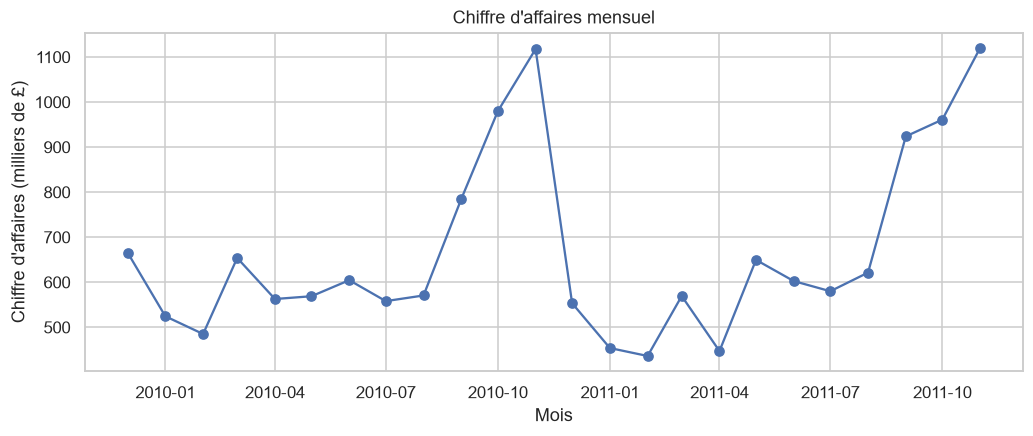

,CA,Factures,Clients
InvoiceDate,,,
2011-06-01,"602,524.41",1374,986
2011-07-01,"580,010.81",1313,945
2011-08-01,"621,376.29",1262,933
2011-09-01,"923,760.68",1724,1252
2011-10-01,"960,961.82",1878,1356
2011-11-01,"1,119,973.56",2630,1656


In [8]:
monthly = df.set_index("InvoiceDate").resample("MS").agg(
    CA=("TotalPrice", "sum"), Factures=("Invoice", "nunique"), Clients=("CustomerID", "nunique"))
# le dernier mois (décembre 2011) n'est que partiellement couvert
monthly = monthly.iloc[:-1]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly["CA"] / 1e3, marker="o")
ax.set_title("Chiffre d'affaires mensuel")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires (milliers de £)")
save(fig, "01_ca_mensuel")
plt.show()
monthly.tail(6)

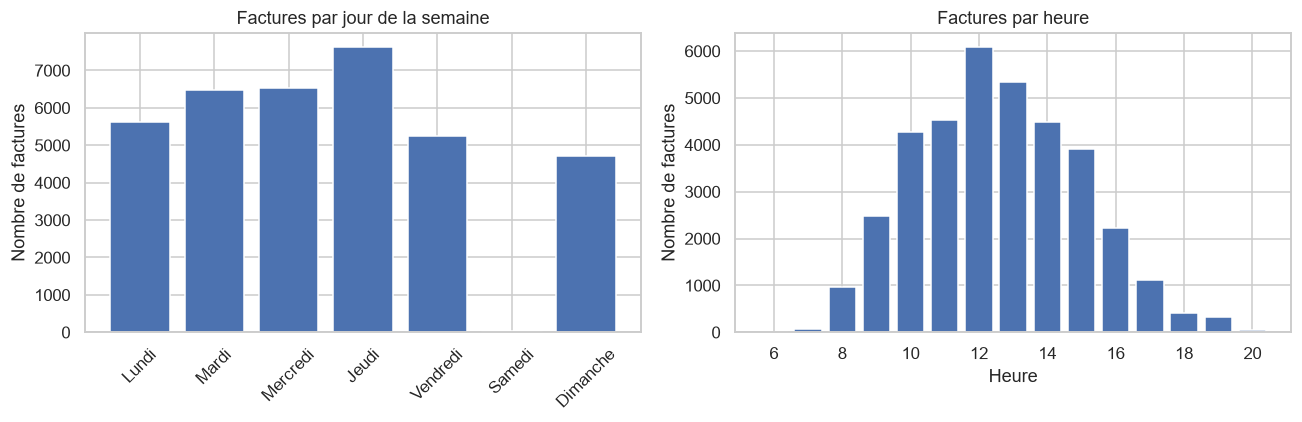

In [9]:
days = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
by_day = df.groupby(df["InvoiceDate"].dt.day_of_week)["Invoice"].nunique().reindex(range(7), fill_value=0)
by_hour = df.groupby(df["InvoiceDate"].dt.hour)["Invoice"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(days, by_day.values)
axes[0].set_title("Factures par jour de la semaine")
axes[0].set_ylabel("Nombre de factures")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(by_hour.index, by_hour.values)
axes[1].set_title("Factures par heure")
axes[1].set_xlabel("Heure")
axes[1].set_ylabel("Nombre de factures")
fig.tight_layout()
save(fig, "02_jour_heure")
plt.show()

## 5. Pays

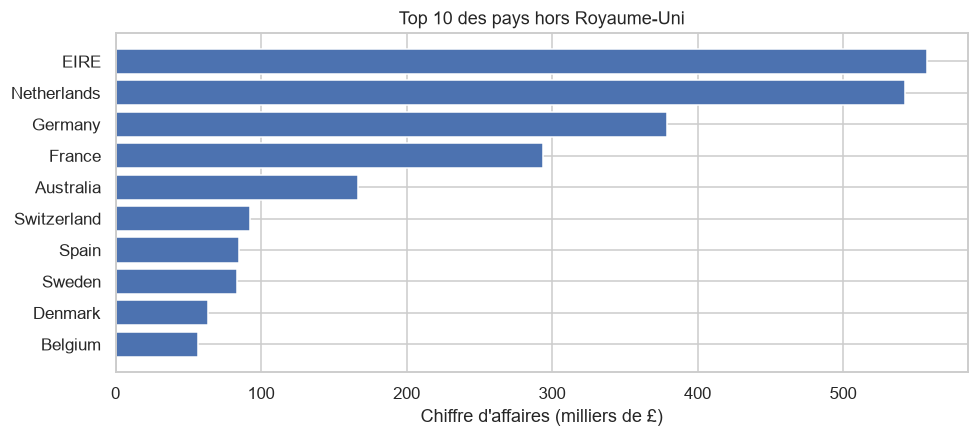

,CA,Clients,Part du CA (%)
Country,,,
United Kingdom,"13,642,047.69",5325,83.50
EIRE,"557,984.23",3,3.42
Netherlands,"542,699.45",22,3.32
Germany,"379,247.15",107,2.32
France,"294,063.60",93,1.80


In [10]:
country = df.groupby("Country").agg(CA=("TotalPrice", "sum"), Clients=("CustomerID", "nunique"))
country["Part du CA (%)"] = 100 * country["CA"] / country["CA"].sum()
country = country.sort_values("CA", ascending=False)

top = country.head(11).iloc[1:]  # hors Royaume-Uni, qui écrase l'échelle
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(top.index[::-1], top["CA"][::-1] / 1e3)
ax.set_title("Top 10 des pays hors Royaume-Uni")
ax.set_xlabel("Chiffre d'affaires (milliers de £)")
save(fig, "03_top_pays")
plt.show()
country.head(5)

## 6. Produits

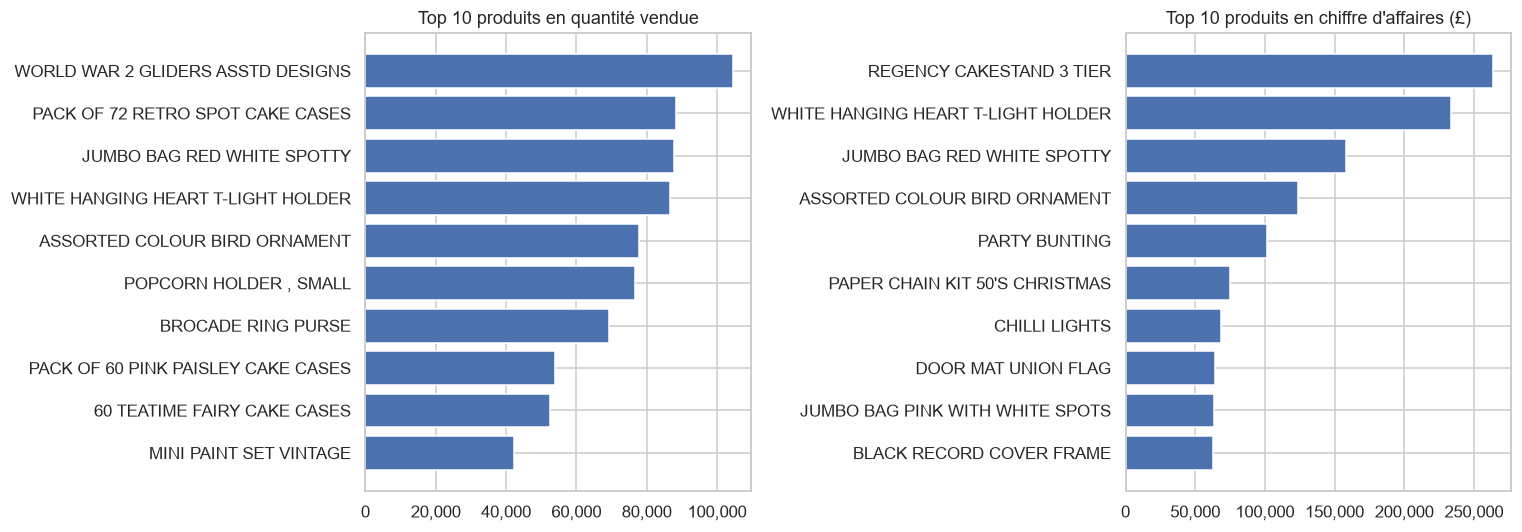

In [11]:
products = df.groupby(["StockCode"]).agg(
    Description=("Description", "first"), Quantité=("Quantity", "sum"), CA=("TotalPrice", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [(axes[0], "Quantité", "Top 10 produits en quantité vendue"),
                       (axes[1], "CA", "Top 10 produits en chiffre d'affaires (£)")]:
    top = products.nlargest(10, col)
    ax.barh(top["Description"].str.slice(0, 35)[::-1], top[col][::-1])
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.tight_layout()
save(fig, "04_top_produits")
plt.show()

## 7. Paniers et clients

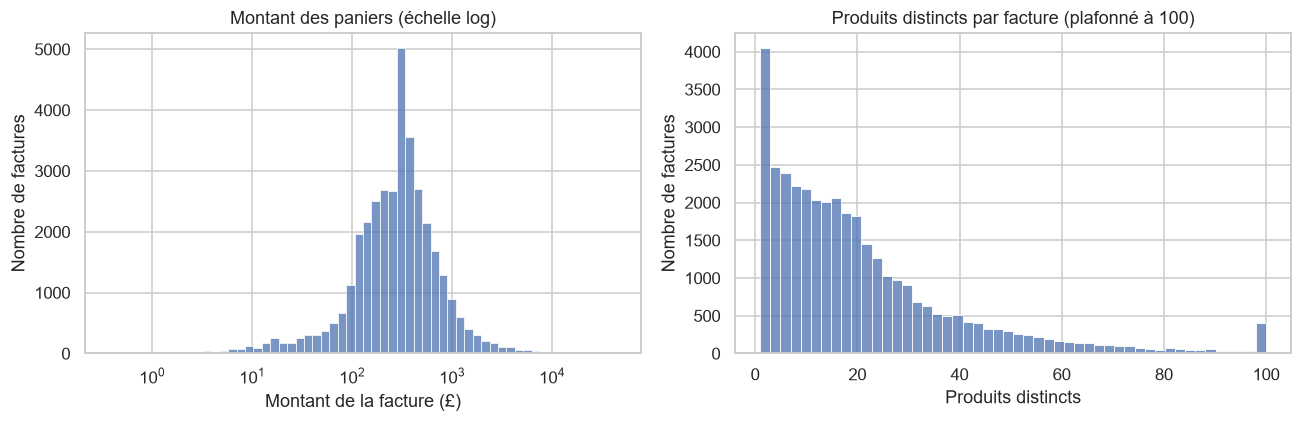

,Montant,Articles
count,"36,267.00","36,267.00"
mean,450.47,20.87
std,908.53,22.32
min,0.38,1.00
25%,157.59,7.00
50%,300.47,15.00
75%,466.88,27.00
max,"43,627.60",540.00


In [12]:
baskets = df.groupby("Invoice").agg(Montant=("TotalPrice", "sum"), Articles=("StockCode", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(baskets["Montant"], bins=60, log_scale=True, ax=axes[0])
axes[0].set_title("Montant des paniers (échelle log)")
axes[0].set_xlabel("Montant de la facture (£)")
axes[0].set_ylabel("Nombre de factures")
sns.histplot(baskets["Articles"].clip(upper=100), bins=50, ax=axes[1])
axes[1].set_title("Produits distincts par facture (plafonné à 100)")
axes[1].set_xlabel("Produits distincts")
axes[1].set_ylabel("Nombre de factures")
fig.tight_layout()
save(fig, "05_paniers")
plt.show()
baskets.describe()

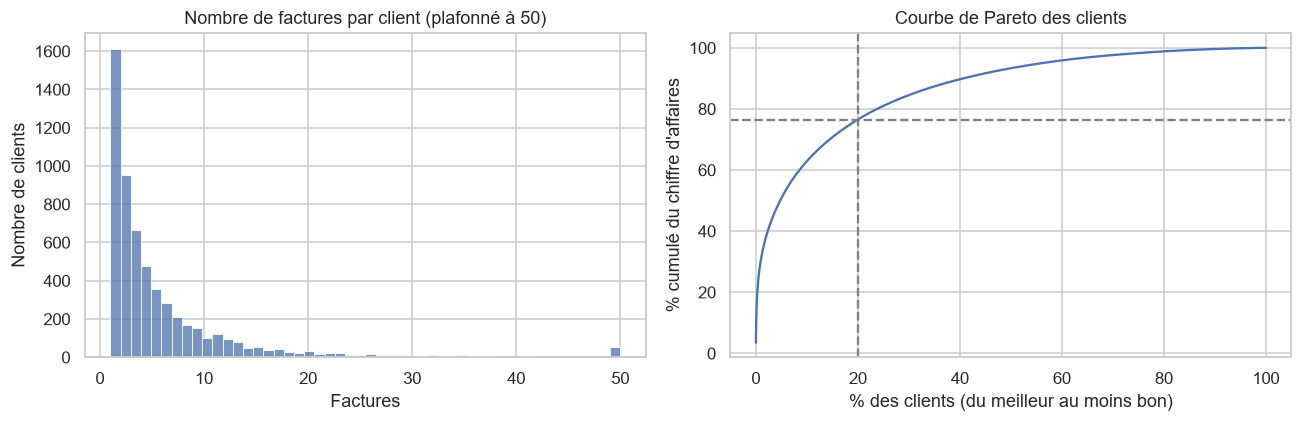

Clients avec un seul achat : 27.6 %
Les 20 % meilleurs clients réalisent 76.5 % du chiffre d'affaires


In [13]:
customers = df.groupby("CustomerID").agg(Factures=("Invoice", "nunique"), CA=("TotalPrice", "sum"))

# Courbe de Pareto : part du CA réalisée par les meilleurs clients
share = customers["CA"].sort_values(ascending=False).cumsum() / customers["CA"].sum()
pct_clients = np.arange(1, len(share) + 1) / len(share)
top20 = share.iloc[int(0.2 * len(share)) - 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(customers["Factures"].clip(upper=50), bins=50, ax=axes[0])
axes[0].set_title("Nombre de factures par client (plafonné à 50)")
axes[0].set_xlabel("Factures")
axes[0].set_ylabel("Nombre de clients")
axes[1].plot(100 * pct_clients, 100 * share.values)
axes[1].axvline(20, color="grey", linestyle="--")
axes[1].axhline(100 * top20, color="grey", linestyle="--")
axes[1].set_title("Courbe de Pareto des clients")
axes[1].set_xlabel("% des clients (du meilleur au moins bon)")
axes[1].set_ylabel("% cumulé du chiffre d'affaires")
fig.tight_layout()
save(fig, "06_clients_pareto")
plt.show()
print(f"Clients avec un seul achat : {100 * (customers['Factures'] == 1).mean():.1f} %")
print(f"Les 20 % meilleurs clients réalisent {100 * top20:.1f} % du chiffre d'affaires")

## 8. Valeurs aberrantes

Méthode de l'écart interquartile (IQR) sur les lignes de transaction. Les distributions sont très
asymétriques : on regarde aussi les cas extrêmes un par un avant de décider.

,Lignes hors IQR,% des lignes,Maximum
Quantity,"49,872.00",6.50,"19,152.00"
Price,"61,176.00",7.97,649.50
TotalPrice,"62,179.00",8.10,"8,925.00"


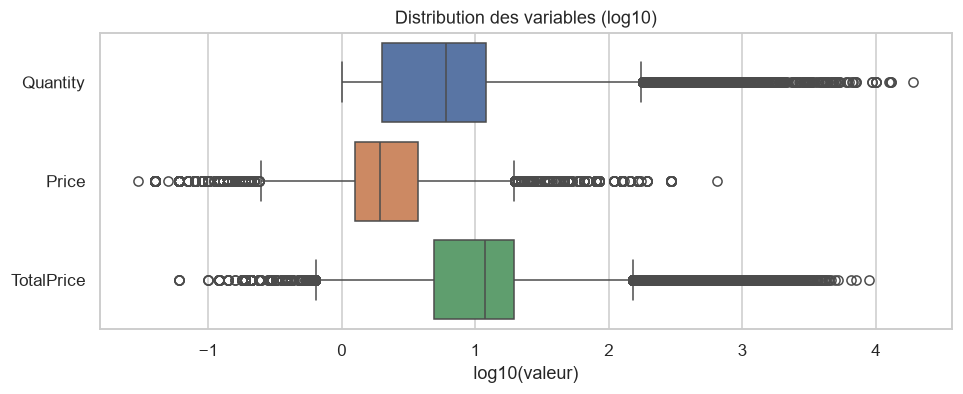

,Invoice,Description,Quantity,Price,TotalPrice,CustomerID,Country
166750,511465,PINK PAPER PARASOL,3500,2.55,"8,925.00",18008,United Kingdom
622165,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72",17450,United Kingdom
486460,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40",15749,United Kingdom
285469,525968,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,"5,179.20",15838,United Kingdom
679940,573003,RABBIT NIGHT LIGHT,2400,2.08,"4,992.00",14646,Netherlands


In [14]:
outliers = pd.DataFrame({
    col: {"Lignes hors IQR": iqr_outlier_mask(df[col]).sum(),
          "% des lignes": 100 * iqr_outlier_mask(df[col]).mean(),
          "Maximum": df[col].max()}
    for col in ["Quantity", "Price", "TotalPrice"]
}).T
display(outliers)

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.boxplot(data=np.log10(df[["Quantity", "Price", "TotalPrice"]]), orient="h", ax=ax)
ax.set_title("Distribution des variables (log10)")
ax.set_xlabel("log10(valeur)")
save(fig, "07_boxplots")
plt.show()

df.nlargest(5, "TotalPrice")[["Invoice", "Description", "Quantity", "Price", "TotalPrice", "CustomerID", "Country"]]

## 9. Conclusion

- **Nettoyage :** 767 351 lignes conservées sur 1 067 371 (71,9 %). La perte vient surtout des lignes sans
  identifiant client (23 %), inutilisables pour une analyse client. Point important : une annulation (« C... »)
  ne supprime pas la commande d'origine. Sans l'étape « Commandes annulées ensuite », des commandes de
  80 995 et 74 215 articles, annulées le jour même, auraient faussé toutes les analyses (ligne maximale :
  168 470 £ avant correction, 8 925 £ après).
- **Volume :** 36 267 factures, 5 838 clients, 4 612 produits, 41 pays, 16,3 M£ de chiffre d'affaires
  (décembre 2009 → décembre 2011).
- **Saisonnalité forte :** le chiffre d'affaires double entre l'été et novembre (≈ 1,1 M£ en novembre 2010 et
  2011). C'est un commerce de cadeaux : la date de coupure du module D devra en tenir compte.
- **Rythme :** quasiment aucune facture le samedi (30 au total), un pic d'activité vers midi.
- **Géographie :** le Royaume-Uni représente 83,5 % du chiffre d'affaires ; l'Irlande (EIRE) arrive deuxième
  avec seulement 3 clients, ce qui suggère des grossistes.
- **Clients :** très forte concentration (loi de Pareto) : les 20 % meilleurs clients réalisent 76,5 % du chiffre
  d'affaires, et 27,6 % des clients n'ont acheté qu'une seule fois. Ces deux constats justifient la segmentation
  RFM du module B et la prédiction du churn du module D.
- **Valeurs aberrantes :** 6 à 8 % des lignes sont hors IQR, mais elles correspondent à des achats en gros
  plausibles (grossistes). Elles sont **conservées** ; les modules suivants utiliseront des transformations
  logarithmiques pour limiter leur influence.

**Suite :** module B — calcul des variables RFM et segmentation des clients.
